# <Paper title>: reproduction and extension

**Student:** <name> · **Paper:** <authors, title, venue, year, link> · **Track:** Docker (ns-3 / Python) or NixNet

**Summary (3-5 sentences):** what the paper claims, what you reproduced, what you changed, and the main result.

> **How to use this template** (delete this box before submitting)
> 1. Keep the sections of the track you use; delete the example sections you do not need.
> 2. Replace the example scenario (`ns3/aanet`, `sim/main.py` or the experiment in `flake.nix`) with your own.
> 3. Every experiment runs through `runner.py`, which caches results in `results/`. Re-running a cell only runs what is missing.
> 4. Before submitting: commit, clone into a fresh folder, follow the README and run this notebook top to bottom (*Kernel → Restart & Run All*).

## 0. Related Work/Setting
A Unmanned aerial vehicle (UAV) swarm is a group of drones that work together in a coordinated, autonomous way. In particular, they must maintain accruate and synchronized state information (position, velocity, heading) even in the face of partial failures and environmental interference. (UAV swarms rely heavily on precise coordination, among others, of their positions). To this effect, UAVs are equipped both with Global Navigation Satellite Systems (GNSS) and Inertial Navigation Systems (INS). GNSS signals can be unreliable in real-world conditions, due to dense vegetation, urban canyons or subterranean environments. In addition, GNSS technologies are vulnerable to spoofing or jamming. So, in attempts to make up for these short-comings, UAVs are also equipped with INS systems. These use accelerometer and gyroscope information to estimate the current position of an UAV, given a starting point. One could think of this as moving through a room with the eyes closed. One is at the door, counts how many steps one takes and how often one turns, and hopefully one would have a rough estimate of where one is in the room. Because INS does not rely on external radio signals, it is harder to spoof and can be used in areas where GNSS fails. However, it is less accurate and the accumulation of small errors in pose estimation can cause the estimated position to drift away from its correct one. The limitations of GNSS and INS as standalone systems speak for the use of collaborative, consensus-driven approaches, that combine GNSS, INS and leverage the connections between UAVs in a swarm as a way to achieve a robust and fault-tolerant state estimation for UAV swarms.<br>
System Model: <br>
For this particular paper, we assume the communication graph among the UAVs to be fully connected and synchronous. So every UAV can has a direct link to every other UAV and we assume that the network conditions are such that we don't need to worry about a message that was sent in time step k only being received on time step k+1. The paper does this so it can focus on sensor faults instead of network delays. We also assume that the UAV carries a ranging sensor of the Received Signal Strength Indicator (RSSI) type. This sensor measures the strength of a received signal and by applying a signal propagation model allows a noisy estimation of distance. A lower received signal means the sender is farther away, whilst a higher means it is closer. Walls, obstacles, antenna orientation and the choice of the propagation model all influence the computed distance, so the result is always noisy. RSSI is used in the paper as a way for the UAV's to have some notion of where all other nodes are (also called internode distances). <br>
Messages between nodes are sent over an authenticated broadcast channel protected by pre-distributed cryptographic keys, so message forgery or tampering are detected. <br>
INS can always be relied upon. Only GNSS sensors can be Byzantine (i.e. up to f can fail)


# Operating Conditions:
A UAV swarm is a speciallized case of a distrbitued system, but it can in some ways still be characterized as one. Swarm consensus should: 
* have low-latency agreements
* operate under strict ressource constraints (limited compute/energy resources; intermittent connectivity) / be lightweight
* be robust agains partial system failure
* ensure termination (all non-faulty agents reach a decision)
* ensure agreement (decisions are consistent)
* ensure integrity (decisions are based on valid inputs)

## 1. High Level Idea
The paper's key idea was to recognize the commonalities between a swarm and a distributed system, and then adapt a well-established consensus algorithm for distributed systems to our scenario. The used protocol is Raft, usually used for coordination of data storage in databases. More importantly, Raft has a lightweithgt leader architecture and is crash-tolerant. It can recover from network partitions, where some nodes get disconnected from the network for some time and upon reconnecting have to synchronize their storage. The paper adapts the Raft algorithm to enable drones to communicated and synchronize their positions over a network, even in partially GNSS denied environments. When GNSS fails, the swarm uses consensus to reconstruct/verify the location and trajectory of affected nodes based on data they shared and how the affected drones where moving prior to failing. In this way, even when individual drones's sensing mechanisms fail, the swarm remains cohesive. The paper's **SwarmRaft** protocol thus makes use of bothe the GNSS and INS data to produce a robust state estimate to reduce the effects of signal failure, spoofing and sensor drift, with it improving the swarm's situational awareness and operational reliability.

## 2. The Workflow
At each time step k, the swarm determines the position of each UAV. To do so, nodes communicate via Raft consensus and elect a leader for that time step. The leader collects every node's position estimate (via GNSS or INS when the other failed) tests to see if the node's reported position is consistent with what the other nodes are seeing, recovers the correct position and sends the results to the nodes. In **SwarmRaft**, so long as n >= 2f + 1 where n is the number of nodes and f the amount of corrupted nodes, the system will be fault tolerant (i.e. if the majority of the nodes is not faulty, the system can recover from incorrectly reported data). <br>
Given a leader for a time step k, the **SwarmRaft** does the following:
1. **SENSE:** Each UAV measures its position (GNSS/INS) and internode distances (each node estimates distance to neighbouring nodes).
2. **INFORM:** Measurements are sent to the leader.
3. **ESTIMATE:** Leader recomputes each UAV's position from range constraints (sanity check).
4. **EVAULUATE:** Leader determines if the received sensor data is faulty or honest based on allowed deviations.
5. **RECOVER:** If sensor data is faulty, that data is replaced with position computed with other drones's estimates.
6. **FINALIZE:** Leader sends final results to all nodes.

## 3. Threat Model
Now we will introduce the attack scenarios that **SwarRaft** is prepared to handle.
1. **GNSS Spoofing Attack:** Attacker is able to distort the position measurements of the GNSS of up to f nodes, causing each node to report a position that is offset by some bias. Our inter-node consistency checks and the consensus mechanism ensure that GNSS readings that deviate significantly from the position estimations of other UAVs get detected.
2. **Ranging-Tampering Attack:** Attacker interferes with the RSSI sensors and is able to create errors in the inter-UAV distance measurements. ?????? (Solution part not clear yet)
3. **Collusion Among Faulty Sensors:** Up to f faulty UAVs decide to collude on sensor information. Compromised nodes coordinate their reported measurements and their votes in the **SwarmRaft** protocol, in hopes of influencing the swarm's decision about the position of a particular "victim" node. Due to the majority requirement, the scheme guarantees that you always have a higher number of honest votes than colluding malicious votes, so no coallition (of size <= f) can force an incorrect decision for the whole swarm.

## 4. The Algorithm in Depth: Pose Estimation
At each time step k $\in$ $\mathbb{N}$ the UAV i $\in$ {1, ..., n} gets two complementary measurements about its state. The GNSS receiver produces a direct, but noisy (see before) readout of the true position x_(i,k): __formula__ . <br>
The INS computes the estimation of the position based on its previous estimation and increments derived from the gyroscopes and accelerometers's behaviour during the time in between step [k-1, k], called the inertial measurements. <br>

In short: INS has high-rate relative motion at the cost of accumulating drift vs GNSS's drift-free absolute position, but with high instant noise. <br>

The information from the two sensors gets cross-checked and each UAV measures its distance to every other UAV. The reading satisfies the formula: __formula__. This just means that the measured distance is the true distance, offset by the measurement noise of the method. This geometric constraint links the true positions of both drones is used to detect inconsistencies in node's measurements (due to GNSS/INS spoofing or drift).

## 5. The Algorithm in Depth: Fault Detection
## 6. The Algorithm in Depth: Position Correction and Recovery


## 0. Setup
`ENGINE="docker"` runs every job in the pinned Docker images and is required for the results you submit.
`ENGINE="local"` runs the same jobs without Docker and is only for debugging.

In [1]:
import os

os.environ.setdefault("ENGINE", "docker")  # set before importing runner
TRACKS = os.environ.get("TRACKS", "ns3,python,nixnet").split(",")  # delete what you do not use

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import runner
from runner import grid, read_iperf3, read_ping, run_nixnet, run_ns3, run_py, sweep

FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def mean_ci(df, by, col):
    """Mean of `col` over seeds with an approximate 95% confidence interval (1.96 x SEM)."""
    g = df.groupby(by)[col]
    out = g.agg(["mean", "std", "count"])
    out["ci95"] = 1.96 * out["std"] / np.sqrt(out["count"])
    return out.reset_index()


pd.Series(runner.environment_info(), name="value").to_frame()  # report this with your results

,value
engine,docker
python,3.12.8
platform,macOS-27.2-arm64-arm-64bit
git_commit,5ceb22f
git_dirty,True
nix,None
docker,"Docker version 29.9.3, build 5457199"
ns3_image,sky-ns3:3.42 None
py_image,sky-py:1.1 sha256:5ca73b4a7f9ad019d912c5e53dbb...


## 1. Experiment design
- **Research question:** <what the experiment answers>
- **Parameters swept:** <names, values, why these values>
- **Fixed parameters:** <and where they come from in the paper>
- **Metrics:** <definitions and units>
- **Repetitions:** <number of seeds/runs and why it is enough>

## 2. ns-3 experiment (Docker track)
Example: AANET snapshot (`ns3/aanet/aanet.cc`). Aircraft in a 1000 km x 1000 km area, air-to-air links within `commRange`,
min-hop routing, 10 random UDP flows. Each job is one `(params, seed)` pair; the seed is passed to ns-3 as `--RngRun`.

In [2]:
if "ns3" in TRACKS:
    ns3_configs = grid(numNodes=[50, 100], commRange=[200_000, 300_000, 400_000], simTime=[10])
    ns3_seeds = range(1, 6)
    ns3_df = sweep(run_ns3, ns3_configs, ns3_seeds)  # one row per flow, per job
    display(ns3_df.head())

In [3]:
if "ns3" in TRACKS:
    # aggregate flows per run first, then compute mean and CI over seeds
    per_run = (ns3_df.groupby(["numNodes", "commRange", "seed"])
               .agg(reachable=("reachable", "mean"), delay_ms=("mean_delay_ms", "mean"))
               .reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, col, label in [(axes[0], "reachable", "Reachable flows (fraction)"),
                           (axes[1], "delay_ms", "Mean end-to-end delay [ms]")]:
        s = mean_ci(per_run, ["numNodes", "commRange"], col)
        for n, g in s.groupby("numNodes"):
            ax.errorbar(g.commRange / 1e3, g["mean"], yerr=g.ci95, marker="o", capsize=3, label=f"{n} aircraft")
        ax.set_xlabel("Air-to-air range [km]")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(FIG / "ns3_reachability_delay.pdf", bbox_inches="tight")

## 3. The authors' code

The paper links its code on GitHub: [kapeldev/SwarmRaft](https://github.com/kapeldev/SwarmRaft). It is small: two Python scripts, one per figure, plus a driver (about 680 lines, numpy and scipy). The scripts simulate only the detection and recovery step. There is no Raft, network or messaging code in them.

We use the code **unchanged**. It is linked into this repository as a git submodule in `sim/swarmraft`. A small wrapper, `sim/swarmraft_sim.py`, lets the template's `runner.py` run it, so every result is cached in `results/` like the template's examples.

> **Run the next cell first.** It downloads the authors' code (`git submodule update --init`) if your clone does not have it yet, and prints the commit it uses.

In [4]:
import subprocess

SIM = "swarmraft_sim.py"            # sim/swarmraft_sim.py: wraps the authors' code
AUTHORS = Path("sim/swarmraft")      # the authors' repository (git submodule)

# Fetch the authors' code if this clone does not have it yet (= `git submodule update --init`)
if not (AUTHORS / "Scaling_Swarm_Error.py").exists():
    fetch = subprocess.run(["git", "submodule", "update", "--init", str(AUTHORS)], capture_output=True, text=True)
    if fetch.returncode != 0:
        raise RuntimeError(f"Could not fetch the authors' code into {AUTHORS} (needs git and internet):\n"
                           f"{fetch.stderr}\nRun `git submodule update --init` in a terminal and retry.")
commit = subprocess.run(["git", "-C", str(AUTHORS), "log", "-1", "--format=%h (%cs) %s"],
                        capture_output=True, text=True).stdout.strip()
print(f"Authors' code in {AUTHORS}: commit {commit}")

FS = range(1, 9)                     # f = 1..8 as in the paper
DIAG = [{"n": 2 * f + 1, "f": f} for f in FS]  # the paper's cases n = 2f + 1
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
AUTHORS_SETTING = "authors' code (noise discarded, τ = 1 cm)"


def run_sim(configs, seed, **fixed):
    """Run sim/swarmraft_sim.py once per config (results cached in results/py/)."""
    return sweep(run_py, [{**c, **fixed} for c in configs], seeds=[seed], script=SIM)


def setting_label(apply_noise, tol):
    """Legend/column label; tolerances below 1 m are written in cm."""
    tau = f"{tol * 100:g} cm" if tol < 1 else f"{tol:g} m"
    return f"noise on, τ = {tau}" if apply_noise else AUTHORS_SETTING

Authors' code in sim/swarmraft: commit 6e9d47d (2025-09-21) Add files via upload


### 3.1 What the code does

Each run is one frozen snapshot of the swarm:

1. **Swarm:** n drones at random positions in a 100 m cube.
2. **Attack:** f drones report a position shifted by up to 30 m per axis (GNSS spoofing). The others report their true position.
3. **Vote:** for every pair, the code compares the distance between their reported positions with the measured distance. A drone that disagrees with more drones than it agrees with is flagged.
4. **Recover:** each flagged drone's position is recomputed from its distances to the unflagged drones (multilateration).
5. **Score:** the error is the distance between recovered and true position, averaged over the spoofed drones.

This is exactly Algorithm 1 of the paper (p. 7).

### 3.2 Reproducing Fig. 1

Fig. 1 shows one snapshot each for (n, f) = (6, 2), (11, 5), (16, 7). Our run gives the same positions as the paper: every spoofed drone is flagged and put back on its true position, and the honest drones are untouched.

,,spoofed,flagged,max_error_m
n,f,,,
6,2,2,2,0.0
11,5,5,5,0.0
16,7,7,7,0.0


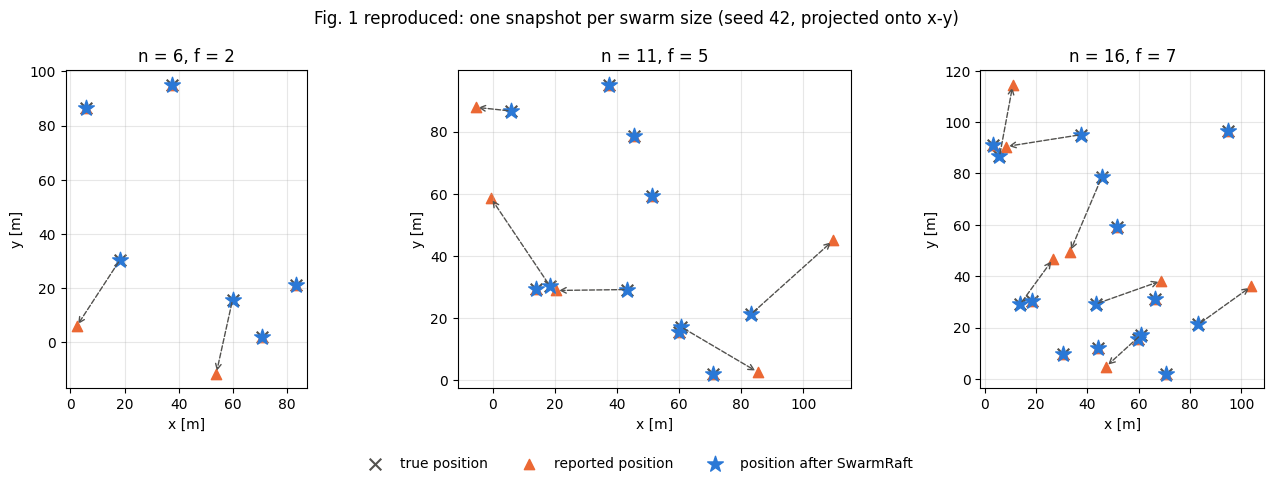

In [5]:
FIG1_CASES = [(6, 2), (11, 5), (16, 7)]
fig1 = run_sim([{"n": n, "f": f, "mode": "scenario"} for n, f in FIG1_CASES], seed=42)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (n, f) in zip(axes, FIG1_CASES):
    d = fig1[(fig1.n == n) & (fig1.f == f)]
    ax.scatter(d.true_x, d.true_y, marker="x", s=70, c=C_GRAY, label="true position")
    ax.scatter(d.reported_x, d.reported_y, marker="^", s=55, c=C_ORANGE, label="reported position")
    ax.scatter(d.recovered_x, d.recovered_y, marker="*", s=140, c=C_BLUE, zorder=3,
               label="position after SwarmRaft")
    for _, r in d[d.spoofed].iterrows():
        ax.annotate("", xy=(r.reported_x, r.reported_y), xytext=(r.true_x, r.true_y),
                    arrowprops=dict(arrowstyle="->", color=C_GRAY, ls="--", lw=1))
    ax.set(title=f"n = {n}, f = {f}", xlabel="x [m]", ylabel="y [m]", aspect="equal")
    ax.grid(alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.suptitle("Fig. 1 reproduced: one snapshot per swarm size (seed 42, projected onto x-y)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "fig1_reproduction.pdf", bbox_inches="tight")

spoofed = fig1[fig1.spoofed]
err = np.linalg.norm(spoofed[["recovered_x", "recovered_y", "recovered_z"]].to_numpy()
                     - spoofed[["true_x", "true_y", "true_z"]].to_numpy(), axis=1)
(spoofed.assign(error_m=err).groupby(["n", "f"])
 .agg(spoofed=("drone", "count"), flagged=("flagged", "sum"), max_error_m=("error_m", "max"))
 .round(4))

### 3.3 Reproducing Fig. 2

Fig. 2 shows, for n = 2f + 1, the mean error of the spoofed drones before and after recovery, over 10,000 runs per point (seed 43, as in the authors' script). The first run takes a few minutes; afterwards the results come from `results/py/`.

In [6]:
fig2 = run_sim(DIAG, seed=43, runs=10_000)  # a few minutes the first time, then cached

stored = pd.DataFrame({"n": np.load(AUTHORS / "ns.npy"),
                       "authors_stored_m": np.load(AUTHORS / "avg_errors.npy")})
summary2 = (fig2.groupby(["n", "f"])
            .agg(spoofed_m=("err_spoofed", "mean"), recovered_m=("err_recovered", "mean"),
                 sd=("err_recovered", "std"), runs=("run", "count"))
            .reset_index().merge(stored, on="n"))
summary2["ci95_m"] = 1.96 * summary2.sd / np.sqrt(summary2.runs)  # error bars in the plot
(summary2[["n", "f", "spoofed_m", "recovered_m", "authors_stored_m"]]
 .rename(columns={"spoofed_m": "error before [m]", "recovered_m": "error after, ours [m]",
                  "authors_stored_m": "error after, authors [m]"})
 .round(3))

,n,f,error before [m],"error after, ours [m]","error after, authors [m]"
0,3,1,28.682,19.002,19.002
1,5,2,28.899,5.503,5.503
2,7,3,28.832,2.293,2.293
3,9,4,28.784,1.234,1.234
4,11,5,28.850,0.854,0.854
5,13,6,28.801,0.522,0.522
6,15,7,28.816,0.408,0.408
7,17,8,28.765,0.287,0.287


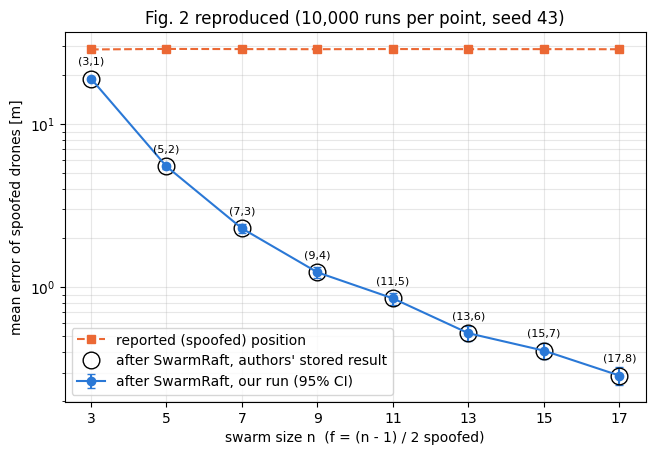

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(summary2.n, summary2.spoofed_m, "s--", c=C_ORANGE, label="reported (spoofed) position")
ax.errorbar(summary2.n, summary2.recovered_m, yerr=summary2.ci95_m, fmt="o-", c=C_BLUE, capsize=3,
            label="after SwarmRaft, our run (95% CI)")
ax.plot(summary2.n, summary2.authors_stored_m, "o", mfc="none", mec="black", ms=12,
        label="after SwarmRaft, authors' stored result")
for n, f, e in summary2[["n", "f", "recovered_m"]].itertuples(index=False):
    ax.annotate(f"({n},{f})", (n, e), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set(yscale="log", xticks=summary2.n, xlabel="swarm size n  (f = (n - 1) / 2 spoofed)",
       ylabel="mean error of spoofed drones [m]", title="Fig. 2 reproduced (10,000 runs per point, seed 43)")
ax.grid(alpha=0.3, which="both")
ax.legend()
fig.savefig(FIG / "fig2_reproduction.pdf", bbox_inches="tight")

**Result.** Our numbers equal the authors' stored results (to within 2 × 10⁻⁷ m); the paper's "from 19 m to 0.28 m" are the first and last of them.

The curve falls because a larger swarm has more honest drones to compute from. With two (n = 3) the position is not determined, since two distances only give a circle; from four on it is. Because the distances carry no noise, the curve says nothing about how the scheme copes with measurement errors.

## 4. Paper vs. code

The code reproduces the figures exactly, but it simulates much less than the paper describes.

| | Paper | Code | Tested in |
|---|---|---|---|
| **Consensus** | Raft: a leader collects all reports and shares the result over WiFi | No Raft, no messages, no network | – |
| **Time and sensors** | Time steps, GNSS noise, INS, GNSS loss | One snapshot; honest drones report their exact position; no INS | – |
| **Range noise** | Measured distances are noisy | Noise is drawn, then discarded | 4.1 |
| **Detection** | Calibrated threshold T = μ + 3σ | Fixed 1 cm tolerance | 4.2 |
| **Attacks** | GNSS spoofing, range tampering, collusion | GNSS spoofing only | – |
| **Evaluation** | All n and f; error distributions; "real-world scenarios" | Only n = 2f + 1; means only; spoofed drones only; random points in a cube | 4.2, 4.3 |

The biggest gap is the first row: Raft is in the title and is the paper's first contribution, but it is not in the code. Below we test the noise and detection rows.

### 4.1 The noise setting has no effect

If the range noise were used, changing it would change the results. We run the authors' code with noise 0 and 0.5 m (same seed, 1000 runs per swarm size) and compare every run.

In [8]:
noise_check = run_sim([{**c, "noise": s} for c in DIAG for s in (0.0, 0.5)], seed=43, runs=1000)
cols = ["err_recovered", "err_spoofed", "honest_moved", "spoofed_missed"]
off, on = (noise_check[noise_check.noise == s].reset_index(drop=True)[cols] for s in (0.0, 0.5))
print(f"{len(off)} runs per noise setting (8 swarm sizes x 1000); identical results: {off.equals(on)}")

8000 runs per noise setting (8 swarm sizes x 1000); identical results: True


### 4.2 Turning the noise on

We keep the noisy distances the code already computes (`sim/swarmraft_variants.py`, one line) and vary the vote tolerance τ. With 0.5 m noise, two honest drones almost never agree to within the authors' 1 cm. We also count honest drones that are wrongly flagged and moved, which the paper's metric ignores.

In [9]:
TOLS = [0.01, 1.0, 2.0, 3.0]  # vote tolerance tau [m]; 0.01 is the authors' value
noisy = run_sim([{**c, "apply_noise": True, "tol": t} for c in DIAG for t in TOLS], seed=43, runs=1000)
authors = noise_check[noise_check.noise == 0.5].assign(apply_noise=False, tol=0.01)
stress = pd.concat([authors, noisy], ignore_index=True)
stress["setting"] = [setting_label(a, t) for a, t in zip(stress.apply_noise, stress.tol)]
summary4 = (stress.groupby(["setting", "n"])
            .agg(recovered_m=("err_recovered", "mean"), honest_moved=("honest_moved", "mean"))
            .reset_index())
order = [AUTHORS_SETTING] + [setting_label(True, t) for t in TOLS]
print("n = 17 (8 spoofed, 9 honest drones), 1000 runs per setting")
(summary4[summary4.n == 17].set_index("setting").loc[order, ["recovered_m", "honest_moved"]]
 .rename(columns={"recovered_m": "error after [m]", "honest_moved": "honest drones moved per run"})
 .round(2))

n = 17 (8 spoofed, 9 honest drones), 1000 runs per setting


,error after [m],honest drones moved per run
setting,,
"authors' code (noise discarded, τ = 1 cm)",0.37,0.00
"noise on, τ = 1 cm",6.38,7.22
"noise on, τ = 1 m",1.12,0.02
"noise on, τ = 2 m",0.94,0.00
"noise on, τ = 3 m",0.97,0.00


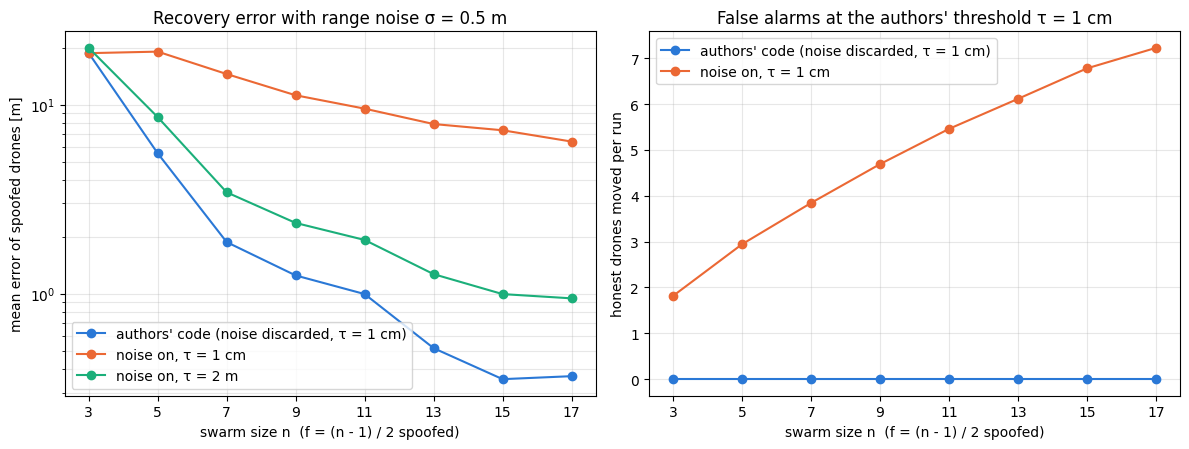

In [10]:
colors = {AUTHORS_SETTING: C_BLUE, setting_label(True, 0.01): C_ORANGE, setting_label(True, 2.0): C_AQUA}
left = list(colors)                                  # error: published, noise on at 1 cm, noise on at 2 m
right = [AUTHORS_SETTING, setting_label(True, 0.01)]  # false alarms at the authors' 1 cm threshold


def draw(ax, settings, column):
    for setting in settings:
        s = summary4[summary4.setting == setting]
        ax.plot(s.n, s[column], "o-", c=colors[setting], label=setting)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
draw(axes[0], left, "recovered_m")
draw(axes[1], right, "honest_moved")
axes[0].set(yscale="log", ylabel="mean error of spoofed drones [m]",
            title="Recovery error with range noise σ = 0.5 m")
axes[1].set(ylabel="honest drones moved per run",
            title="False alarms at the authors' threshold τ = 1 cm")
for ax in axes:
    ax.set(xlabel="swarm size n  (f = (n - 1) / 2 spoofed)", xticks=summary2.n)
    ax.grid(alpha=0.3, which="both")
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / "noise_stress_test.pdf", bbox_inches="tight")

**Result** at n = 17 (1000 runs per point, so the noise-free value is 0.37 m rather than Fig. 2's 0.29 m):

- **Authors' 1 cm tolerance:** 7 of 9 honest drones are moved per run, and the spoofed drones' error rises from 0.37 m to 6.4 m.
- **2 m tolerance:** no honest drone is moved; the error is 0.94 m, 2.5 times the noise-free value.
- 1 m still moves some honest drones; 3 m is slightly worse than 2 m.

The scheme works with noise only with a tolerance the paper never states, and at a higher error.

### 4.3 What the mean hides

The paper describes medians, interquartile ranges and outliers for Fig. 2, but the figure shows only means. From the 10,000 runs per point of Section 3.3:

In [11]:
by_n = fig2.groupby("n").err_recovered
pd.DataFrame({"mean [m]": by_n.mean(), "median [m]": by_n.median(),
              "runs above 1 m [%]": 100 * by_n.apply(lambda e: (e > 1).mean())}).round(2)

,mean [m],median [m],runs above 1 m [%]
n,,,
3,19.00,14.14,96.33
5,5.50,0.00,33.10
7,2.29,0.00,14.20
9,1.23,0.00,8.41
11,0.85,0.00,6.54
13,0.52,0.00,4.27
15,0.41,0.00,3.55
17,0.29,0.00,2.81


**Result.** From n = 5 on, the median error is zero: in most runs every spoofed drone is recovered exactly, and the mean comes from a few runs that fail by metres. At n = 17, "0.28 m" means exact in 97 % of runs and metres off in the other 3 %.

### 4.4 Summary

- **Reproduction:** both figures are reproduced exactly with the authors' code, run through the course template.
- **What they show:** voting plus multilateration on one noise-free snapshot. No Raft, network, time or INS.
- **Noise:** with the authors' own noise switched on, their 1 cm tolerance breaks the scheme; 2 m repairs it at 2.5 times the error.
- **Statistics:** the means in Fig. 2 come from a few failed runs; the median error is zero from n = 5 on.

## 5. NixNet experiment (NixNet track)
Example: ground station → aircraft relay → ground station (`flake.nix`). Each air link adds a one-way delay `d` (and optional loss),
so the expected RTT is about 4·d. Experiments are named `relay-d<delay>-l<loss>`; each run is stored in `results/nixnet/<name>/<run>/`.
Start Jupyter with `nix develop -c jupyter lab` so that `nix` is available.

In [12]:
if "nixnet" in TRACKS:
    rows = []
    for exp in [f"relay-d{d}-l{l}" for d in (1, 5, 20) for l in (0, 1)]:
        for run_dir in run_nixnet(exp, runs="1-3"):
            client = run_dir / "gs-west"
            rows.append({"experiment": exp, "run": run_dir.name,
                         **read_ping(client / "ping.txt"), **read_iperf3(client / "iperf3.json")})
    nix_df = pd.DataFrame(rows)
    nix_df[["delay_ms", "loss_pct_cfg"]] = nix_df.experiment.str.extract(r"d(\d+)-l(\d+)").astype(int)
    display(nix_df.head())

In [13]:
if "nixnet" in TRACKS:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for loss, g in nix_df.groupby("loss_pct_cfg"):
        s = mean_ci(g, "delay_ms", "rtt_avg_ms")
        axes[0].errorbar(s.delay_ms, s["mean"], yerr=s.ci95, marker="o", capsize=3, label=f"loss {loss}%")
        s = mean_ci(g, "delay_ms", "throughput_mbps")
        axes[1].errorbar(s.delay_ms, s["mean"], yerr=s.ci95, marker="o", capsize=3, label=f"loss {loss}%")
    d = np.array(sorted(nix_df.delay_ms.unique()))
    axes[0].plot(d, 4 * d, "k--", lw=1, label="expected 4·d")
    axes[0].set_ylabel("RTT [ms]")
    axes[1].set_ylabel("TCP throughput [Mbit/s]")
    for ax in axes:
        ax.set_xlabel("One-way delay per air link [ms]")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(FIG / "nixnet_rtt_throughput.pdf", bbox_inches="tight")

## 6. Results and discussion
- **Reproduction:** which results of the paper you reproduced, and how closely (numbers, figures side by side).
- **Differences:** where your results differ and why (model simplifications, parameters, randomness).
- **Extension:** what you changed or added, and what you learned from it.
- **Limitations:** what your experiment cannot show.

## 7. Reproducibility
- **Environment:** the table printed in section 0 (engine, image IDs or Nix version, git commit).
- **How to reproduce:** see `README.md`. Results are cached in `results/` with a `.json` file per job describing how it was produced.
- **Checklist before submitting:**
  - [ ] all results produced with `ENGINE="docker"` (Docker track) or via `nix develop` (NixNet track)
  - [ ] `flake.lock` / pinned `requirements*.txt` committed
  - [ ] fresh clone + README + *Restart & Run All* works
  - [ ] git working tree clean (`git_dirty` is `False` above)